# 03 Scaling to all events and the five class target

**Notebook 3 of 6, xBD building damage assessment**

The damage models in notebook 2 only saw hurricanes and tornadoes and answered
damaged yes/no. Two extensions here:

1. all events instead of a subset, with a wider validation set
2. the full five class target (background, no-damage, minor, major, destroyed)
   instead of damaged yes/no

Requires `01_data_check.ipynb` to have run once.

## 0. Setup

In [1]:
import os
import sys
from pathlib import Path

root = Path.cwd()
while not (root / "config.py").exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root))

import numpy as np
from PIL import Image
import matplotlib.pyplot as pl
import torch
from torch.utils.data import DataLoader
from collections import Counter

import config
from common import data, crops, models, losses, train, evaluate, plots

pl.rcParams["figure.dpi"] = 120
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

paths = {split: found for split, found in data.resolve_splits(config.DATA_ROOT).items()
         if split in ("train", "test", "tier3")}
file_lists = {split: data.list_pre_images(paths[split]["images"]) for split in paths}
for split, files in file_lists.items():
    print(f"{split}: {len(files)} pre-disaster images")


/DATA/schrepel/ml_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cuda
train: 2746 pre-disaster images
test: 917 pre-disaster images
tier3: 6288 pre-disaster images


## 1. Data

Same building filter as in notebook 2, but without restricting the event types.

In [2]:
all_building_files = []
for split in paths:
    for pre_image in file_lists[split]:
        stem = pre_image.replace("_pre_disaster.png", "")
        target = np.array(Image.open(
            os.path.join(paths[split]["targets"], f"{stem}_pre_disaster_target.png")))
        if (target > 0).mean() >= config.MIN_BUILDING_FRACTION:
            all_building_files.append((split, stem))

train_files = [(s, stem) for s, stem in all_building_files if s in ("train", "tier3")]
val_files = [(s, stem) for s, stem in all_building_files if s == "test"]

event_counts_train = Counter(stem.split("_")[0] for _, stem in train_files)
event_counts_val = Counter(stem.split("_")[0] for _, stem in val_files)

print(f"{len(train_files)} training images over {len(event_counts_train)} events")
print(f"{len(val_files)} validation images over {len(event_counts_val)} events")

4836 training images over 19 events
676 validation images over 10 events


## 2. Validation sets

The set from notebook 2 held hurricane crops only. Scaling to all events needs a
wider one: 12 crops from every test image that passes the building filter, drawn
with the same rules as the training crops. The hurricane set is kept alongside
it so the result stays directly comparable to notebook 2.

In [3]:
ALL_EVENTS_VAL_TILES_PATH = config.VAL_TILES_DIR / "val_damage_raw_tiles_all_events.pt"

if not ALL_EVENTS_VAL_TILES_PATH.exists():
    tiles = crops.draw_raw_tiles(val_files, paths, config.N_VAL_CROPS)
    torch.save(tiles, ALL_EVENTS_VAL_TILES_PATH)
    print(f"saved {len(tiles)} tiles to {ALL_EVENTS_VAL_TILES_PATH}")

In [4]:
val_tiles_all = train.load_val_tiles("val_damage_raw_tiles_all_events.pt")
val_tiles_hurricane = train.load_val_tiles("val_damage_raw_tiles.pt")

crops.describe_tiles(val_tiles_all, "all events")
crops.describe_tiles(val_tiles_hurricane, "hurricanes only")

loaded /DATA/schrepel/xbd_new/val_tiles/val_damage_raw_tiles_all_events.pt (8112 tiles)


loaded /DATA/schrepel/xbd_new/val_tiles/val_damage_raw_tiles.pt (4596 tiles)


all events: 8112 tiles, 81.8% positive, 3.07% damaged building pixels


hurricanes only: 4596 tiles, 69.3% positive, 3.87% damaged building pixels


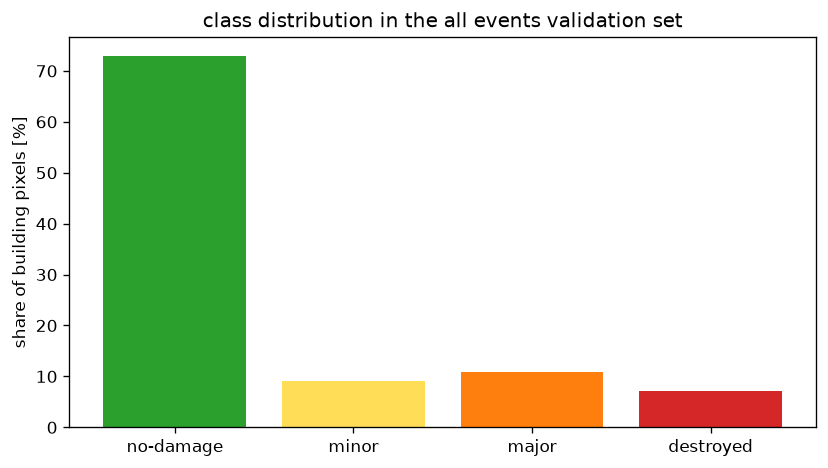

In [5]:
pixel_counts = np.zeros(5, dtype=np.int64)
for _, _, target_tile, _ in val_tiles_all:
    values, counts = np.unique(target_tile, return_counts=True)
    for v, c in zip(values, counts):
        pixel_counts[int(v)] += int(c)

building_counts = pixel_counts[1:]

pl.figure(figsize=(7, 4))
pl.bar([config.FIVE_CLASS_NAMES[c] for c in range(1, 5)],
       100 * building_counts / building_counts.sum(),
       color=["#2ca02c", "#ffdd57", "#ff7f0e", "#d62728"])
pl.ylabel("share of building pixels [%]")
pl.title("class distribution in the all events validation set")
pl.tight_layout()
pl.show()

## 3. Datasets, model and training loop

In [6]:
val_loader_hurricane = DataLoader(
    crops.FixedDamageDataset(val_tiles_hurricane, crops.damage_to_three_class),
    batch_size=config.BATCH_SIZE, shuffle=False)
val_loader_all_3class = DataLoader(
    crops.FixedDamageDataset(val_tiles_all, crops.damage_to_three_class),
    batch_size=config.BATCH_SIZE, shuffle=False)
val_loader_all_5class = DataLoader(
    crops.FixedDamageDataset(val_tiles_all, crops.damage_identity),
    batch_size=config.BATCH_SIZE, shuffle=False)

## 4. Three classes on all events

Architecture and hyperparameters are identical to variant B, only the data basis
is larger. Both validation sets are tracked during training; the checkpoint
follows the hurricane loss so the comparison with notebook 2 stays clean.

In [7]:
if not (config.CKPT_DIR / "damage_full_best.pt").exists():
    train_loader_full = DataLoader(
        crops.DamageDataset(train_files, paths, crops.damage_to_three_class, n_crops=12, augment=True),
        batch_size=config.BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True)

    torch.manual_seed(357)
    model_full = models.UNet(in_channels=6, out_channels=3, base_filters=64, dropout_p=0.2).to(device)

    train.train_model(model_full, train_loader_full, [val_loader_hurricane, val_loader_all_3class],
                config.EPOCHS, config.LEARNING_RATE, device,
                config.CKPT_DIR / "damage_full_best.pt", config.HISTORY_DIR / "history_full.pt",
                loss_fn=losses.MultiClassDiceLoss(n_classes=3, dice_weight=0.5), checkpoint_on=0)

In [8]:
model_full = models.UNet(in_channels=6, out_channels=3, base_filters=64, dropout_p=0.2).to(device)
train.load_checkpoint(model_full, "damage_full_best.pt", device)

loaded /DATA/schrepel/xbd_new/checkpoints/damage_full_best.pt


UNet(
  (enc1): DoubleConv(
    (block): Sequential(
      (0): Conv2d(6, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (enc2): DoubleConv(
    (block): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (enc3): DoubleConv(
    (block): S

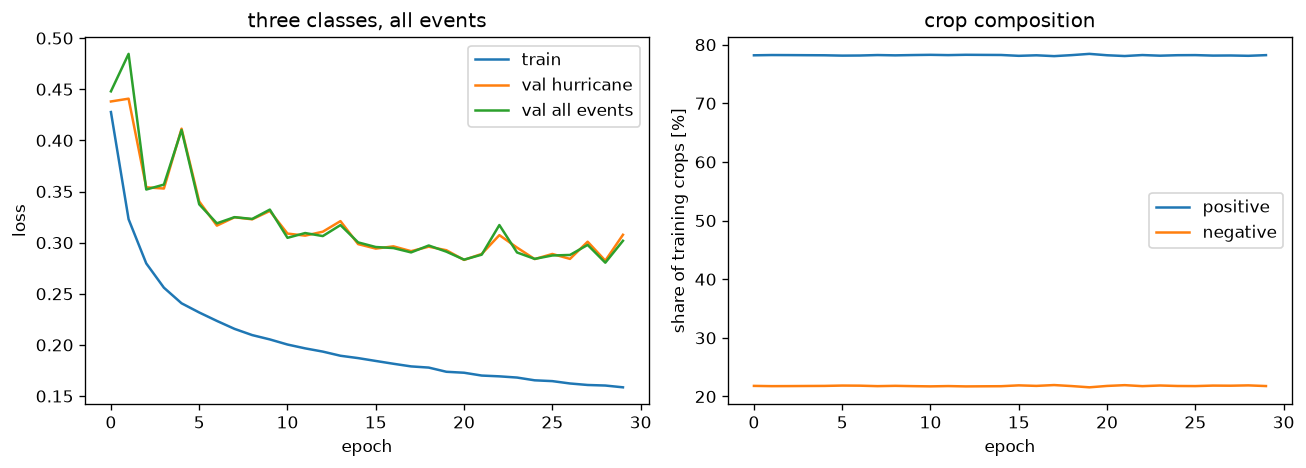

In [9]:
plots.plot_history(train.load_history("history_full.pt"), "three classes, all events",
             val_labels=("val hurricane", "val all events"))

In [10]:
results_full_hurricane = evaluate.per_class_metrics(model_full, val_loader_hurricane, 3, device)
results_full_all = evaluate.per_class_metrics(model_full, val_loader_all_3class, 3, device)

evaluate.print_metrics(results_full_hurricane, config.THREE_CLASS_NAMES, "validated on hurricanes")
print()
evaluate.print_metrics(results_full_all, config.THREE_CLASS_NAMES, "validated on all events")

validated on hurricanes
       class   precision    recall      F1
  background       0.983     0.991   0.987
    building       0.781     0.726   0.752
     damaged       0.750     0.676   0.711

validated on all events
       class   precision    recall      F1
  background       0.976     0.987   0.982
    building       0.842     0.776   0.808
     damaged       0.756     0.676   0.714


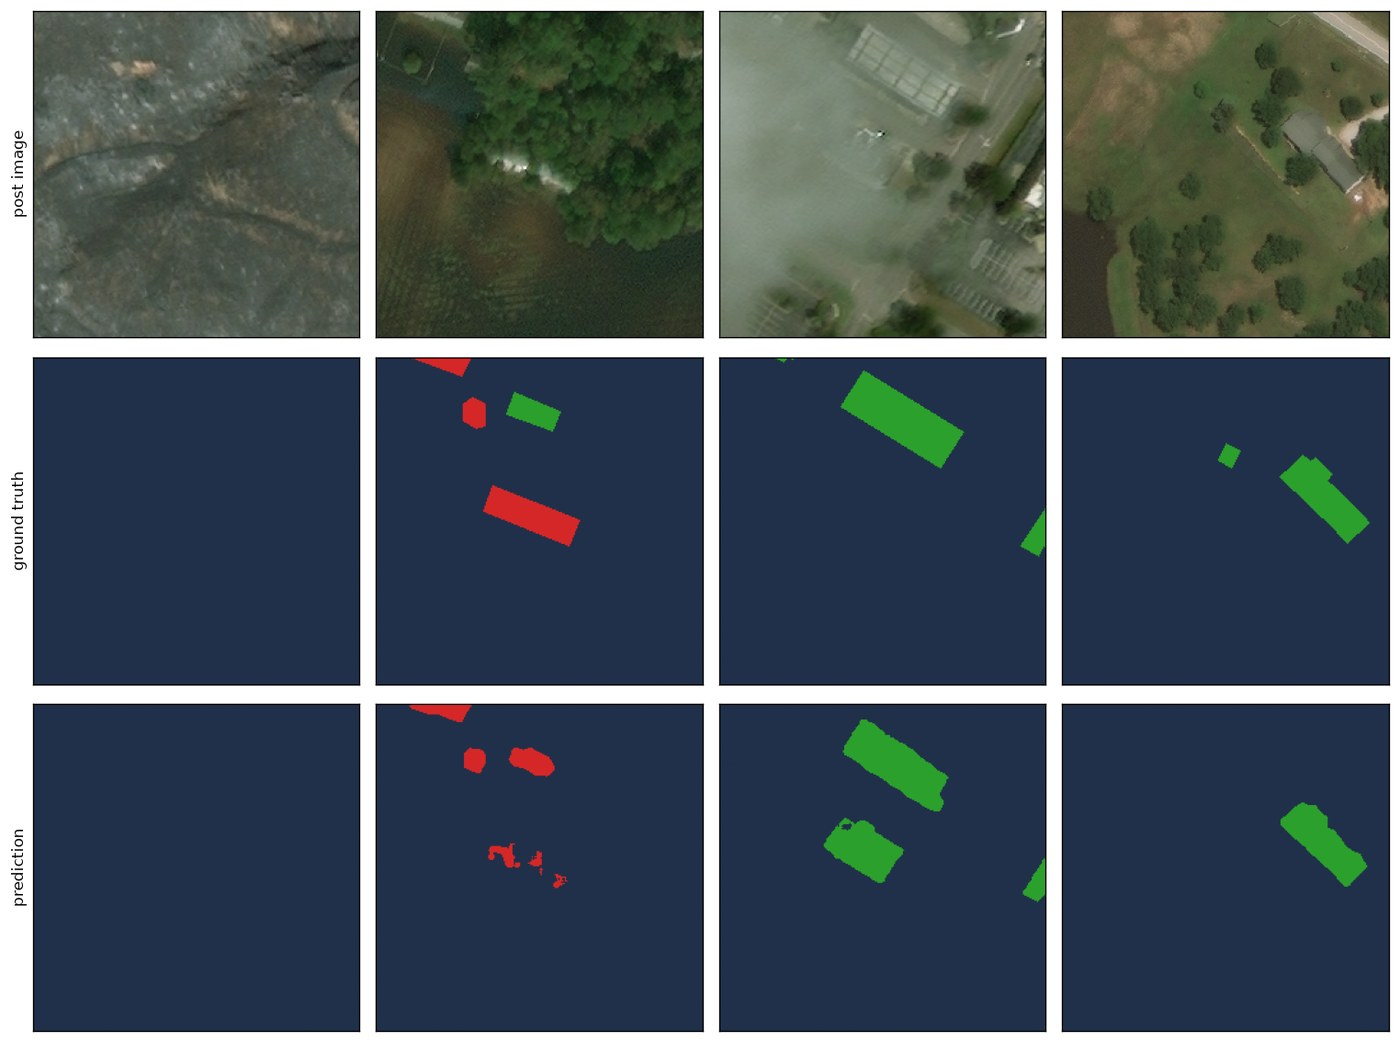

In [11]:
plots.show_examples(plots.make_predictor(model_full, device), val_tiles_all,
              crops.damage_to_three_class, plots.THREE_CLASS_CMAP, n_classes=3)

## 5. Five classes

Same setup with `out_channels=5` and the raw target, so the model predicts the
damage grade instead of damaged yes/no.

In [12]:
if not (config.CKPT_DIR / "damage_5class_best.pt").exists():
    train_loader_5class = DataLoader(
        crops.DamageDataset(train_files, paths, crops.damage_identity, n_crops=12, augment=True),
        batch_size=config.BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True)

    torch.manual_seed(357)
    model_5class = models.UNet(in_channels=6, out_channels=5, base_filters=64, dropout_p=0.2).to(device)

    train.train_model(model_5class, train_loader_5class, [val_loader_all_5class],
                config.EPOCHS, config.LEARNING_RATE, device,
                config.CKPT_DIR / "damage_5class_best.pt", config.HISTORY_DIR / "history_5class.pt",
                loss_fn=losses.MultiClassDiceLoss(n_classes=5, dice_weight=0.5))

In [13]:
model_5class = models.UNet(in_channels=6, out_channels=5, base_filters=64, dropout_p=0.2).to(device)
train.load_checkpoint(model_5class, "damage_5class_best.pt", device)

loaded /DATA/schrepel/xbd_new/checkpoints/damage_5class_best.pt


UNet(
  (enc1): DoubleConv(
    (block): Sequential(
      (0): Conv2d(6, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (enc2): DoubleConv(
    (block): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (enc3): DoubleConv(
    (block): S

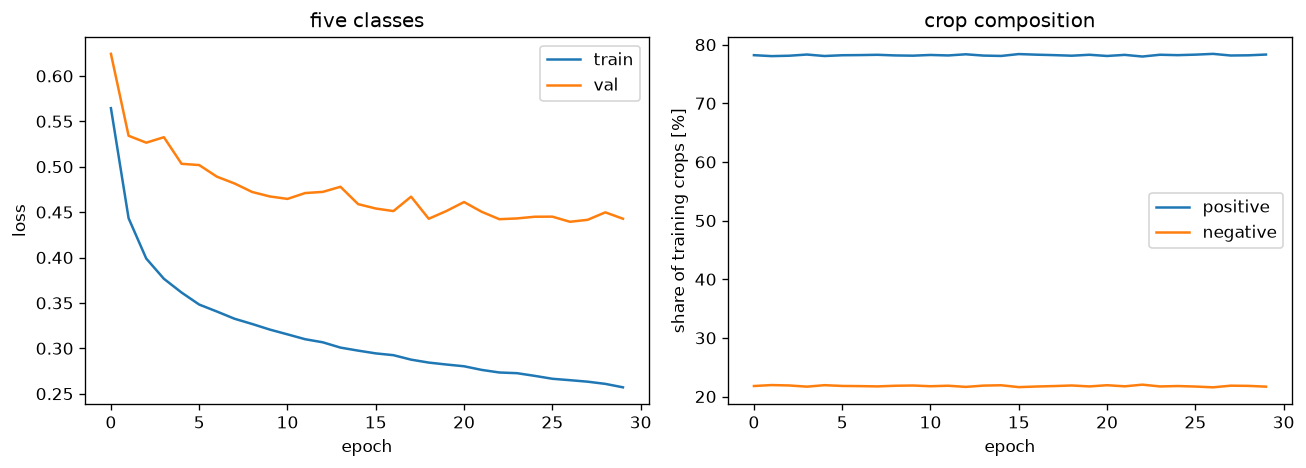

In [14]:
plots.plot_history(train.load_history("history_5class.pt"), "five classes")

In [15]:
results_5class = evaluate.per_class_metrics(model_5class, val_loader_all_5class, 5, device)
evaluate.print_metrics(results_5class, config.FIVE_CLASS_NAMES, "five class U-Net")

five class U-Net
       class   precision    recall      F1
  background       0.977     0.984   0.980
   no-damage       0.820     0.780   0.800
       minor       0.427     0.399   0.413
       major       0.639     0.592   0.615
   destroyed       0.737     0.667   0.700


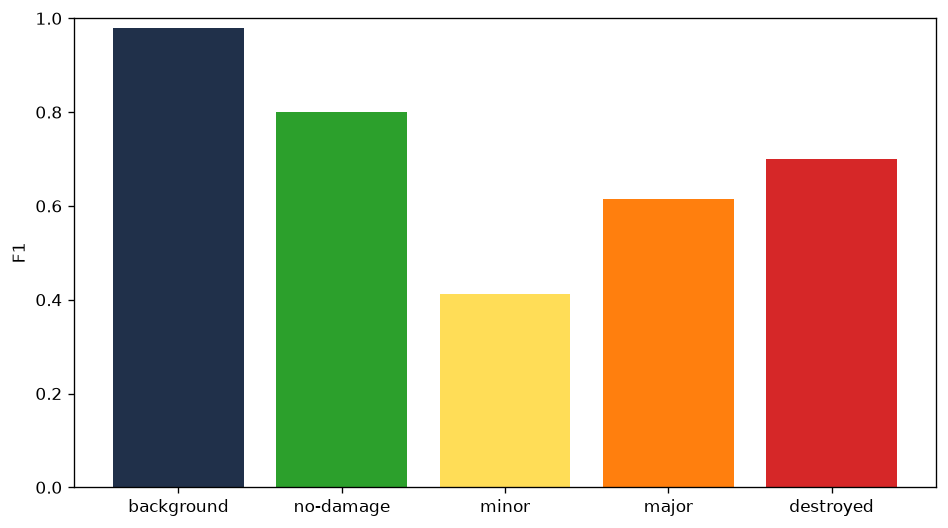

In [16]:
pl.figure(figsize=(8, 4.5))
pl.bar([config.FIVE_CLASS_NAMES[c] for c in range(5)], [results_5class[c][2] for c in range(5)],
       color=["#20304a", "#2ca02c", "#ffdd57", "#ff7f0e", "#d62728"])
pl.ylabel("F1")
pl.ylim(0, 1)
pl.tight_layout()
pl.show()

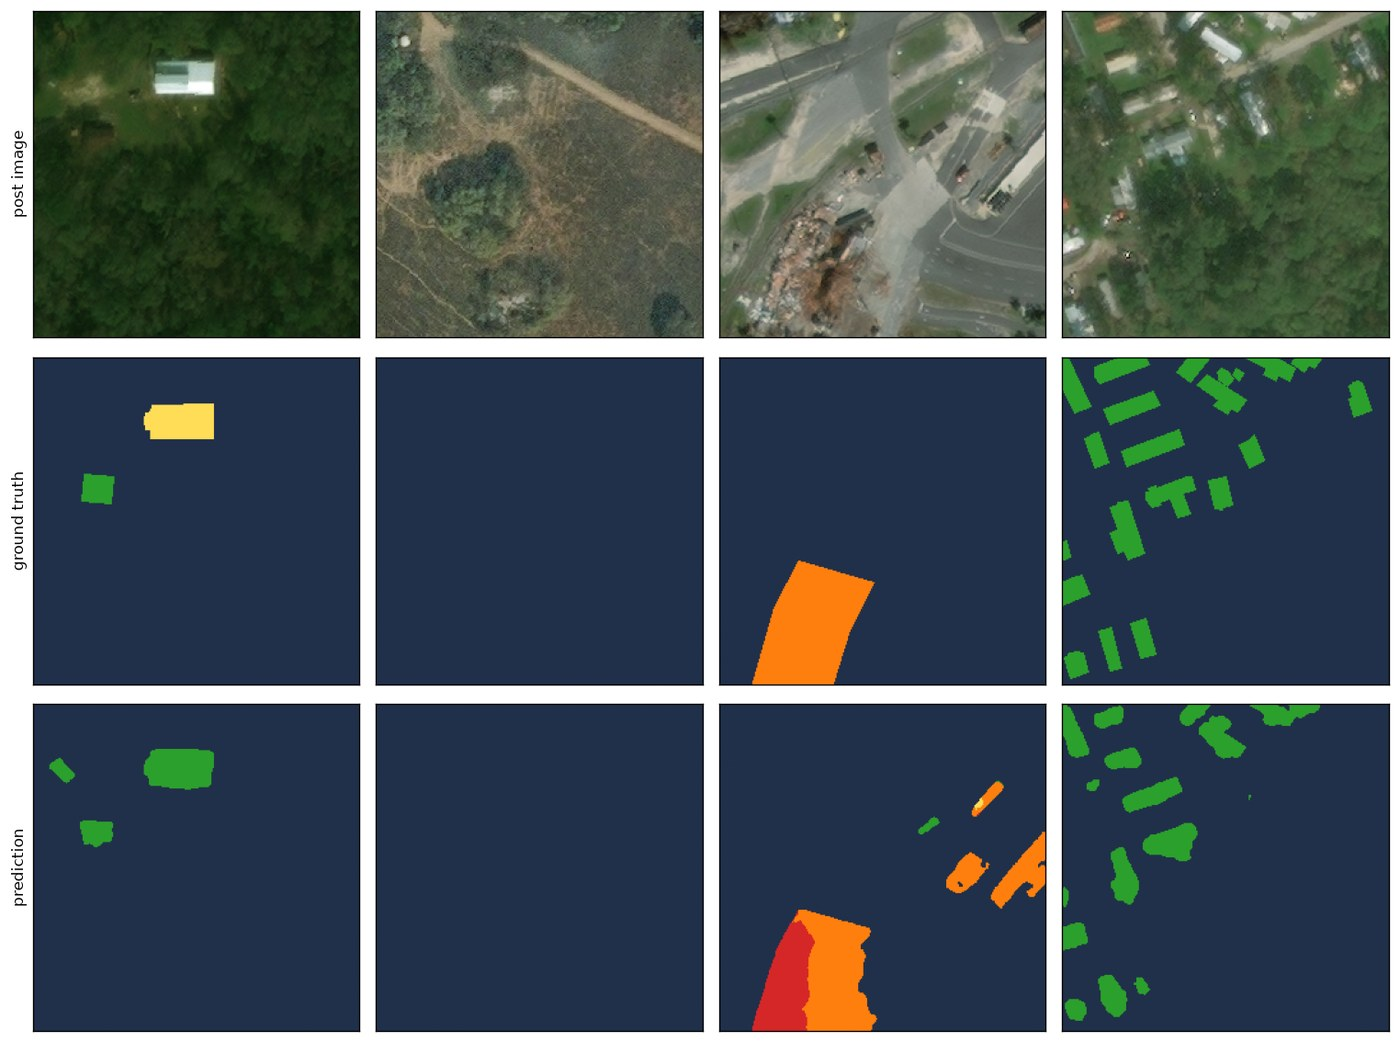

In [17]:
plots.show_examples(plots.make_predictor(model_5class, device), val_tiles_all,
              crops.damage_identity, plots.FIVE_CLASS_CMAP, n_classes=5)

## 6. Three classes against five

To compare the two targets, classes 2 to 4 of the five class model are collapsed
into damaged, which turns both models into an answer to the same question.

In [18]:
def aggregated_f1(model, loader, device, damage_from=2, building_from=1):
    """F1 for damaged and for building detected, independent of the class count."""
    model.eval()
    counts = {"damage": [0, 0, 0], "building": [0, 0, 0]}

    with torch.no_grad():
        for inputs, targets, _ in loader:
            inputs, targets = inputs.to(device), targets.to(device)
            preds = model(inputs).argmax(dim=1)
            for key, threshold in [("damage", damage_from), ("building", building_from)]:
                pred_mask, target_mask = (preds >= threshold), (targets >= threshold)
                counts[key][0] += (pred_mask & target_mask).sum().item()
                counts[key][1] += (pred_mask & ~target_mask).sum().item()
                counts[key][2] += (~pred_mask & target_mask).sum().item()

    out = {}
    for key, (tp, fp, fn) in counts.items():
        p = tp / (tp + fp) if tp + fp else 0.0
        r = tp / (tp + fn) if tp + fn else 0.0
        out[key] = (p, r, 2 * p * r / (p + r) if p + r else 0.0)
    return out


aggregated = {
    "three classes": aggregated_f1(model_full, val_loader_all_3class, device),
    "five classes": aggregated_f1(model_5class, val_loader_all_5class, device),
}

print(f"{'model':<16s}{'precision':>12s}{'recall':>10s}{'F1 damaged':>13s}{'F1 building':>14s}")
for name, agg in aggregated.items():
    p, r, f1 = agg["damage"]
    print(f"{name:<16s}{p:>12.3f}{r:>10.3f}{f1:>13.3f}{agg['building'][2]:>14.3f}")

model              precision    recall   F1 damaged   F1 building
three classes          0.756     0.676        0.714         0.850
five classes           0.723     0.668        0.694         0.842
